# Regresión Logística y Softmax (Multiclase)

**Objetivos de aprendizaje**
- Distinguir **regresión lineal** vs **clasificación** (logística y softmax).
- Entender la **función sigmoide** y la **frontera de decisión**.
- Formular la **pérdida log-loss** (binaria) y **entropía cruzada** (multiclase).
- Derivar **gradientes** y aplicar **L2** (ridge) en clasificación.
- Implementar y validar funciones clave con **tests unitarios**.
- Entrenar modelos simples con **gradiente descendente** y evaluar **accuracy**.

---

## 1. De regresión lineal a clasificación
La regresión lineal modela una variable continua. En clasificación binaria, queremos una **probabilidad** $P(y=1\mid \mathbf{x}) \in (0,1)$.
El modelo lineal $z = \mathbf{w}^\top \mathbf{x} + b$ se pasa por una **no linealidad sigmoide**:
$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$
y la probabilidad estimada es $\hat{p} = \sigma(z)$. La **frontera de decisión** para umbral 0.5 es $\mathbf{w}^\top \mathbf{x} + b = 0$.

## 2. Pérdida y gradientes (binario)
Para datos $\{(\mathbf{x}_i, y_i)\}_{i=1}^m $ con $ y_i\in\{0,1\} $:
$$
\mathcal{L}_{\text{bin}}(\mathbf{w},b)= -\frac{1}{m}\sum_{i=1}^m \left[ y_i\log \hat{p}_i + (1-y_i)\log(1-\hat{p}_i) \right].
$$
Gradiente:
$$
\nabla_{\mathbf{w}} \mathcal{L} = \frac{1}{m} \mathbf{X}^\top(\hat{\mathbf{p}}-\mathbf{y}), \quad
\frac{\partial \mathcal{L}}{\partial b} = \frac{1}{m}\sum_{i=1}^m (\hat{p}_i - y_i).
$$
Regularización **L2** con $\lambda$:
$$
\mathcal{L}_\lambda = \mathcal{L} + \frac{\lambda}{2m}\|\mathbf{w}\|_2^2,\quad
\nabla_{\mathbf{w}} \mathcal{L}_\lambda = \frac{1}{m} \mathbf{X}^\top(\hat{\mathbf{p}}-\mathbf{y}) + \frac{\lambda}{m}\mathbf{w}.
$$
(El sesgo $b$ no se regulariza habitualmente.)

## 3. Multiclase con Softmax
Para $K$ clases, el modelo produce **logits** $ \mathbf{z} = \mathbf{W}^\top \mathbf{x} + \mathbf{b}\in\mathbb{R}^K$.  
Softmax convierte logits en probabilidades:
$$
\text{softmax}(\mathbf{z})_k = \frac{e^{z_k}}{\sum_{j=1}^K e^{z_j}}.
$$
Pérdida (entropía cruzada) con one-hot $ \mathbf{y} \in \{0,1\}^K $:
$$
\mathcal{L}_{\text{mc}}(\mathbf{W},\mathbf{b}) = -\frac{1}{m}\sum_{i=1}^m \sum_{k=1}^K y_{ik} \log \hat{p}_{ik}.
$$
Gradiente clásico:
$$
\nabla_{\mathbf{W}} \mathcal{L}_{\text{mc}} = \frac{1}{m}\mathbf{X}^\top(\hat{\mathbf{P}} - \mathbf{Y}),\quad
\nabla_{\mathbf{b}} \mathcal{L}_{\text{mc}} = \frac{1}{m}\sum_{i=1}^m (\hat{\mathbf{p}}_i - \mathbf{y}_i).
$$
Con **L2** sobre $ \mathbf{W} $: añadir $ \frac{\lambda}{m}\mathbf{W} $ al gradiente de $ \mathbf{W} $.

---

## 4. Esqueleto de implementación y pruebas
A continuación se incluyen funciones clave y **tests unitarios** que validan:
- **Estabilidad numérica** de `sigmoid` y `softmax`.
- **Consistencia** de pérdidas y gradientes (binario y multiclase).
- **Entrenamiento** en datos sintéticos con accuracy esperada mínima.

### Utilidades básicas (completar TODOs)

In [27]:
import numpy as np

def sigmoid(z):
    """Devuelve sigma(z) de forma estable y vectorizada.
    TODO: implementar con recorte para evitar overflow.
    """
    # TODO
    z_recorte = np.clip(z, -500, 500)
    return 1/(1+np.exp(-z_recorte))
    

def softmax(Z):
    """Softmax fila a fila de forma estable.
    Acepta (m,K) o (K,) y devuelve mismas dimensiones.
    TODO: implementar con centrado por fila.
    """
    # TODO
    Z = Z - np.max(Z, axis=-1, keepdims=True) #CENTRAR POR FILA
    exp_z = np.exp(Z)
    sumatoria = np.sum(exp_z, axis=-1, keepdims=True) #SUMATORIA FILA A FILA
    return exp_z/sumatoria

def binary_cross_entropy(y_true, y_prob, eps=1e-12):
    """Pérdida log-loss binaria.
    TODO: proteger con clip y devolver media.
    """
    # TODO
    y_prob = np.max(eps,np.min(1-eps,y_prob))
    return -(1/y_true.size)*(np.sum(y_true*np.log(y_prob)+(1-y_true)*np.log(1-y_prob)))

def multiclass_cross_entropy(Y_true, P_pred, eps=1e-12):
    """Entropía cruzada multiclase.
    TODO: proteger con clip y devolver media por muestra.
    """
    # TODO
    P_pred = np.max(eps,np.min(1-eps,P_pred))
    return  -np.sum(Y_true*np.log(P_pred))

def one_hot(y, K):
    """Devuelve matriz one-hot (m,K)."""
    # TODO
    for i in range (0, K.size):
        for j in range (0, K.size):
            if y[j] == K[j]:
                m[i][j] = 1
            else:
                m[i][j] = 0
    return  m 

### Gradientes — Logística binaria con L2 (TODOs)

In [56]:
def logistic_loss_and_grads(X, y, w, b, l2=0.0):
    """Devuelve (loss, grad_w, grad_b, probs).
    TODO: implementar siguiendo la formulación dada en la teoría.
    """
    # TODO
    N = X.shape[0]
    z = np.dot(X,w) + b
    z = np.clip(z, -500, 500)
    probs = y_gorrito = 1/(1+np.exp(-z))
    loss = (-np.sum(y*np.log(y_gorrito+ 1e-15)+(1-y)*np.log(1-y_gorrito+ 1e-15))/N)+((l2/(2*N))*np.sum(w**2))
    error  = (y_gorrito - y)
    grad_w = np.dot(X.T,error)/N+(l2/N)*w
    grad_b = np.mean(error)
    return loss, grad_w, grad_b, probs

### Gradientes — Softmax multiclase con L2 (TODOs)

In [ ]:
def softmax_loss_and_grads(X, y_int, W, b, l2=0.0):
    """Devuelve (loss, grad_W, grad_b, P).
    TODO: implementar siguiendo la formulación dada en la teoría.
    """
    # TODO
    N = X.shape[0]
    K = W.shape[1]
    z = np.dot(X,W) + b
    z = z - np.max(z, axis=1, keepdims=True)
    P = y_gorrito = np.exp(z) / np.sum(np.exp(z), axis=1, keepdims=True)
    #MATRIZ DE Y EN FORMATO ONE HOT
    y = np.zeros((N, K))
    y[np.arange(N), y_int] = 1.0
    loss = -1/N*np.sum(y*np.log(y_gorrito+1e-15))+l2/(2*N)*np.sum(np.sum(W**2))
    e = (y_gorrito - y)
    grad_w = 1/N*np.dot(X.T,e)+l2/N*W
    grad_b = np.mean(e, axis=0, keepdims=True)
    return loss, grad_w, grad_b, P

### Entrenadores simples (GD) — (TODOs)

In [98]:
def fit_logistic_gd(X, y, lr=0.1, iters=1000, l2=0.0):
    # TODO: inicializar, lazo GD y actualizar con gradientes
    N, D = X.shape
    if y.ndim == 1: 
        w = np.zeros(D)
        b = 0.0
        for i in range(iters):
            z = np.dot(X,w)+b
            z = np.clip(z, -500, 500)
            y_gorrito = 1/(1+np.exp(-z))
            error = y_gorrito - y
            w -= lr * (np.dot(X.T, error) / N + (l2 / N) * w)
            b -= lr * np.mean(error)
        return w, b
    else:
        K = y.shape[1]
        w = np.random.randn(D,K)*0.01
        b = np.zeros((1, K))
        y_int = np.argmax(y, axis=1)
    
        for i in range(iters):
            l, grad_w, grad_b, P = softmax_loss_and_grads(X, y_int, w, b, l2=l2)
            w -= lr * grad_w
            b -= lr * grad_b
        
        return w, b

def fit_softmax_gd(X, y_int, lr=0.1, iters=1000, l2=0.0, K=None):
    # TODO: inicializar, lazo GD y actualizar con gradientes
    N=X.shape[0]
    y = np.zeros((N, K))
    y[np.arange(N), y_int] = 1.0
    return fit_logistic_gd(X, y, lr, iters, l2)

## Tests unitarios (autocorrección) — NO editar

In [57]:
# 1) Sigmoid y softmax (propiedades básicas)
try:
    a = np.array([-1000, 0, 1000], dtype=float)
    s = sigmoid(a)
    assert np.allclose(s[[0,2]], [0.0, 1.0], atol=1e-12)
    assert np.isclose(s[1], 0.5)


    Z = np.array([[10, 10], [0, 10], [3, -3]], dtype=float)
    P = softmax(Z)
    # filas suman 1
    assert np.allclose(P.sum(axis=1), 1.0, atol=1e-12)
    # invariancia por traslación
    P2 = softmax(Z + 5.0)
    assert np.allclose(P, P2, atol=1e-12)
    print("Test 1 OK")
except Exception as e:
    print("Test 1 Error:", e)

Test 1 OK


In [58]:
# 2) Gradientes binarios: comparación numérica (aprox)
try:
  rng = np.random.default_rng(0)
  m, d = 40, 5
  X = rng.normal(size=(m,d))
  true_w = rng.normal(size=d)
  true_b = 0.5
  y = (rng.random(m) <  sigmoid(X@true_w + true_b)).astype(float)

  w = rng.normal(size=d)
  b = 0.1
  l2 = 0.7

  def f_w(wvec):
    loss, _, _, _ = logistic_loss_and_grads(X, y, wvec, b, l2=l2)
    return loss

  eps = 1e-6
  num = np.zeros_like(w)
  for j in range(d):
    w1 = w.copy(); w1[j] += eps
    w2 = w.copy(); w2[j] -= eps
    num[j] = (f_w(w1) - f_w(w2)) / (2*eps)

  loss, gw, gb, _ = logistic_loss_and_grads(X, y, w, b, l2=l2)
  assert np.allclose(gw, num, rtol=2e-3, atol=2e-3)
  print("Test 2 OK")
except Exception as e:
  print("Test 2 Error:", e)

Test 2 OK


In [69]:
# 3) Gradientes softmax: numérico sobre W
try:
    rng = np.random.default_rng(1)
    m, d, K = 60, 4, 3
    X = rng.normal(size=(m,d))
    W = rng.normal(size=(d,K))
    b = rng.normal(size=(K,))
    y_int = rng.integers(0, K, size=m)
    l2 = 0.3

    def f_W(Wmat):
        loss, _, _, _ = softmax_loss_and_grads(X, y_int, Wmat, b, l2=l2)
        return loss

    eps = 1e-6
    num = np.zeros_like(W)
    for i in range(d):
        for k in range(K):
            W1 = W.copy(); W1[i,k] += eps
            W2 = W.copy(); W2[i,k] -= eps
            num[i,k] = (f_W(W1) - f_W(W2)) / (2*eps)

    loss, gW, gb, _ = softmax_loss_and_grads(X, y_int, W, b, l2=l2)
    assert np.allclose(gW, num, rtol=3e-3, atol=3e-3)
    print("Test 3 OK")
except Exception as e:
    print("Test 3 Error:", e)

Test 3 OK


In [94]:
# 4) Entrenamiento binario en datos separables suaves
try:
    rng = np.random.default_rng(42)
    m, d = 200, 2
    X_pos = rng.normal(loc=1.0, scale=0.8, size=(m//2, d))
    X_neg = rng.normal(loc=-1.0, scale=0.8, size=(m//2, d))
    X = np.vstack([X_pos, X_neg])
    y = np.hstack([np.ones(m//2), np.zeros(m//2)])

    w, b = fit_logistic_gd(X, y, lr=0.2, iters=1000, l2=0.01)
    probs = sigmoid(X@w + b)
    yhat = (probs >= 0.5).astype(int)
    acc = (yhat == y).mean()
    assert acc >= 0.9
    print("Test 4 OK — acc =", acc)
except Exception as e:
    print("Test 4 Error:", e)

Test 4 OK — acc = 0.975


In [99]:
# 5) Entrenamiento softmax en blobs multiclase
try:
    rng = np.random.default_rng(7)
    m_per, d, K = 120, 2, 3
    centers = np.array([[2,2], [-2,0], [0,-3]], dtype=float)
    X = np.vstack([centers[k] + rng.normal(scale=0.8, size=(m_per,d)) for k in range(K)])
    y = np.hstack([np.full(m_per, k) for k in range(K)])
except Exception as e:
    print("Test 5 Error:", e)
try:
    W, b = fit_softmax_gd(X, y, lr=0.2, iters=1000, l2=0.01, K=K)
    P = softmax(X@W + b)
    yhat = np.argmax(P, axis=1)
    acc = (yhat == y).mean()
    assert acc >= 0.85
    print("Test 5 OK — acc =", acc)
except Exception as e:
    print("Test 5 Error:", e)

Test 5 OK — acc = 1.0


## Ejercicios propuestos (extras)
1. **Regularización y margen:** Repite el experimento binario variando $\lambda\in\{0, 0.01, 0.1, 1.0\}$ y discute el efecto sobre el **overfitting** y la frontera.
2. **Umbral de decisión** Realiza una gráfica sobre el comportamiento de la Regresión Logística vaiando el umbral 0.5. 

# Regresión Logística y Softmax

In [100]:
import matplotlib.pyplot as plt
import numpy as np

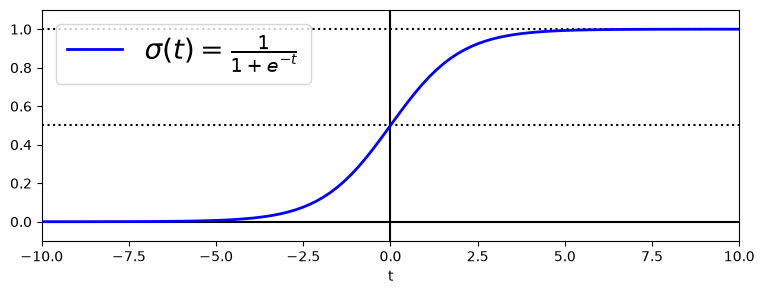

In [101]:
t = np.linspace(-10, 10, 100)
sig = 1 / (1 + np.exp(-t))
plt.figure(figsize=(9, 3))
plt.plot([-10, 10], [0, 0], "k-")
plt.plot([-10, 10], [0.5, 0.5], "k:")
plt.plot([-10, 10], [1, 1], "k:")
plt.plot([0, 0], [-1.1, 1.1], "k-")
plt.plot(t, sig, "b-", linewidth=2, label=r"$\sigma(t) = \frac{1}{1 + e^{-t}}$")
plt.xlabel("t")
plt.legend(loc="upper left", fontsize=20)
plt.axis([-10, 10, -0.1, 1.1])
plt.show()

In [102]:
from sklearn import datasets
iris = datasets.load_iris()
list(iris.keys())
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

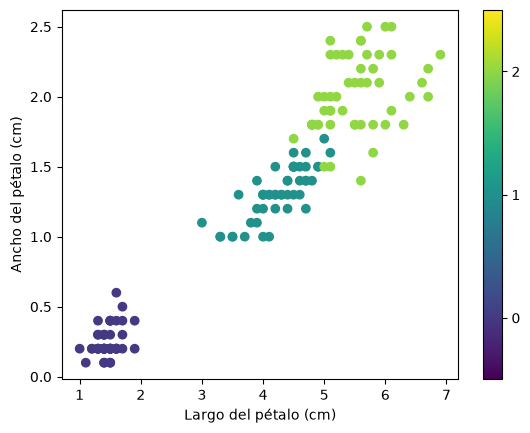

In [103]:

plt.scatter(iris["data"][:, 2], iris["data"][:, 3], c=iris["target"])
plt.xlabel("Largo del pétalo (cm)")
plt.ylabel("Ancho del pétalo (cm)")
# pinta legenda de los colores
plt.colorbar(ticks=[0, 1, 2]) # codifica las clases con su nombre
plt.clim(-0.5, 2.5) # limita los colores entre -0.5 y 2.5
plt.show()

In [104]:
X = iris["data"][:, 3:]  # Me quedo con el ancho del petalo
y = (iris["target"] == 2).astype(int)  # 1 si es Iris-Virginica, 0 en caso contrario

In [105]:
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(solver="liblinear", random_state=42) # solver="liblinear" 
# para datasets pequeños este solver funciona con mejor rendimiento
log_reg.fit(X, y)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1

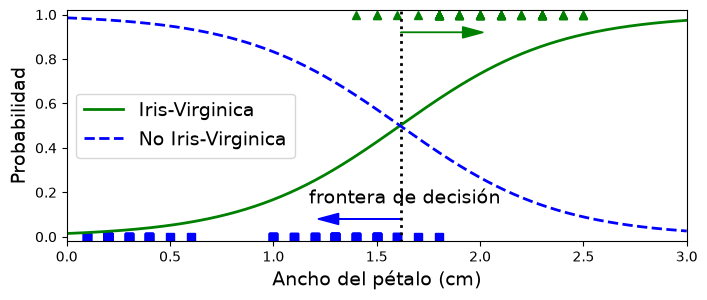

In [106]:
X_new = np.linspace(0, 3, 1000).reshape(-1, 1)
y_proba = log_reg.predict_proba(X_new)

frontera_decision = X_new[y_proba[:, 1] >= 0.5][0].item() # el primer valor donde la probabilidad
# de ser Iris-Virginica es mayor o igual que 0.5    

plt.figure(figsize=(8, 3))
plt.plot(X[y==0], y[y==0], "bs")
plt.plot(X[y==1], y[y==1], "g^")
plt.plot([frontera_decision, frontera_decision], [-1, 2], "k:", linewidth=2)
plt.plot(X_new, y_proba[:, 1], "g-", linewidth=2, label="Iris-Virginica")
plt.plot(X_new, y_proba[:, 0], "b--", linewidth=2, label="No Iris-Virginica")
plt.text(frontera_decision+0.02, 0.15, "frontera de decisión", fontsize=14, color="k", ha="center")
plt.arrow(frontera_decision, 0.08, -0.3, 0, head_width=0.05, head_length=0.1, fc='b', ec='b')
plt.arrow(frontera_decision, 0.92, 0.3, 0, head_width=0.05, head_length=0.1, fc='g', ec='g')
plt.xlabel("Ancho del pétalo (cm)", fontsize=14)
plt.ylabel("Probabilidad", fontsize=14)
plt.legend(loc="center left", fontsize=14)
plt.axis([0, 3, -0.02, 1.02])
plt.show()

In [107]:
print(log_reg.predict([[1.7]]))
print(log_reg.predict_proba([[1.7]]))

[1]
[[0.44316529 0.55683471]]


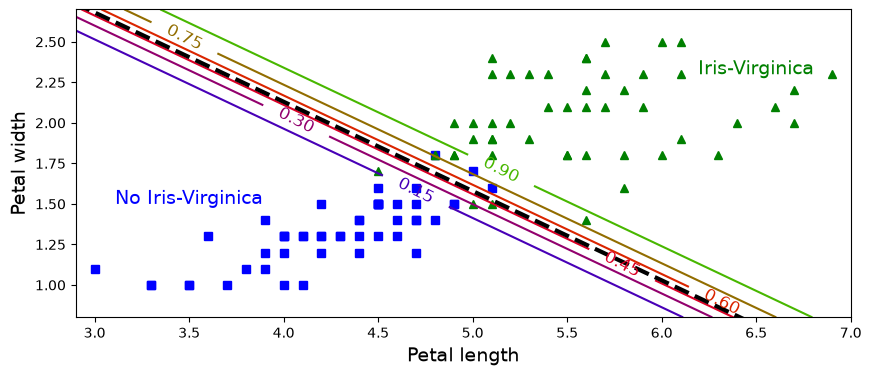

In [108]:
X = iris["data"][:, (2, 3)]  # petal length, petal width
y = (iris["target"] == 2).astype(int)

log_reg = LogisticRegression(solver="liblinear", C=10**10, random_state=42)
log_reg.fit(X, y)

x0, x1 = np.meshgrid(
        np.linspace(2.9, 7, 500).reshape(-1, 1),
        np.linspace(0.8, 2.7, 200).reshape(-1, 1),
    )
X_new = np.c_[x0.ravel(), x1.ravel()]

y_proba = log_reg.predict_proba(X_new)

plt.figure(figsize=(10, 4))
plt.plot(X[y==0, 0], X[y==0, 1], "bs")
plt.plot(X[y==1, 0], X[y==1, 1], "g^")

zz = y_proba[:, 1].reshape(x0.shape)
contour = plt.contour(x0, x1, zz, cmap=plt.cm.brg)


left_right = np.array([2.9, 7])
boundary = -(log_reg.coef_[0][0] * left_right + log_reg.intercept_[0]) / log_reg.coef_[0][1]

plt.clabel(contour, inline=1, fontsize=12)
plt.plot(left_right, boundary, "k--", linewidth=3)
plt.text(3.5, 1.5, "No Iris-Virginica", fontsize=14, color="b", ha="center")
plt.text(6.5, 2.3, "Iris-Virginica", fontsize=14, color="g", ha="center")
plt.xlabel("Petal length", fontsize=14)
plt.ylabel("Petal width", fontsize=14)
plt.axis([2.9, 7, 0.8, 2.7])
plt.show()

In [109]:
X = iris["data"][:, (2, 3)]  # petal length, petal width
y = iris["target"]

# multinomial es el modo por defecto en multiclase; el argumento multi_class
# se eliminó en scikit-learn 1.8, por eso ya no se pasa.
softmax_reg = LogisticRegression(solver="lbfgs", C=10, random_state=42)
softmax_reg.fit(X, y)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following as

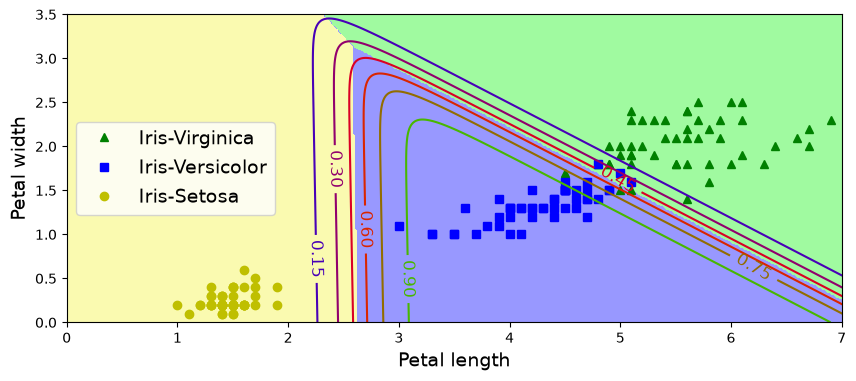

In [110]:
x0, x1 = np.meshgrid(
        np.linspace(0, 8, 500).reshape(-1, 1),
        np.linspace(0, 3.5, 200).reshape(-1, 1),
    )
X_new = np.c_[x0.ravel(), x1.ravel()]


y_proba = softmax_reg.predict_proba(X_new)
y_predict = softmax_reg.predict(X_new)

zz1 = y_proba[:, 1].reshape(x0.shape)
zz = y_predict.reshape(x0.shape)

plt.figure(figsize=(10, 4))
plt.plot(X[y==2, 0], X[y==2, 1], "g^", label="Iris-Virginica")
plt.plot(X[y==1, 0], X[y==1, 1], "bs", label="Iris-Versicolor")
plt.plot(X[y==0, 0], X[y==0, 1], "yo", label="Iris-Setosa")

from matplotlib.colors import ListedColormap
custom_cmap = ListedColormap(['#fafab0','#9898ff','#a0faa0'])

plt.contourf(x0, x1, zz, cmap=custom_cmap)
contour = plt.contour(x0, x1, zz1, cmap=plt.cm.brg)
plt.clabel(contour, inline=1, fontsize=12)
plt.xlabel("Petal length", fontsize=14)
plt.ylabel("Petal width", fontsize=14)
plt.legend(loc="center left", fontsize=14)
plt.axis([0, 7, 0, 3.5])
plt.show()

In [111]:
print(softmax_reg.predict_proba([[5, 1.5]]))
print(softmax_reg.predict([[5, 1.5]]))
print(np.sum(softmax_reg.predict_proba([[5, 1.5]])))

[[6.93664207e-06 6.18115138e-01 3.81877925e-01]]
[1]
1.0000000000000002
